# Telco Customer Churn: Data Visualization Project

**Goal:** understand who leaves a telecom provider and why, using 7,043 customers and 21 attributes.
Every chart below is followed by a short findings note.

In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, recall_score, precision_score
import warnings
warnings.filterwarnings("ignore")

In [2]:
# style
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9b9a94"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
PAL = {"No": BLUE, "Yes": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
})

In [3]:
# load
df = pd.read_csv("Telco-Customer-Churn - cleaned.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Findings: dataset overview**

- The data has 7,043 rows and 21 columns, with no duplicate customer IDs and no null values.
- `TotalCharges` is stored as text. It contains 11 blank entries, all belonging to customers with a tenure of 0 months (new sign-ups who have not been billed yet), so they are converted to numbers and set to 0.
- `SeniorCitizen` is numeric (0/1) while every other categorical column holds text labels. It is relabeled for charts below.

In [5]:
# clean
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
overall = df["ChurnFlag"].mean() * 100
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


**Findings: numeric summary**

- Tenure ranges from 0 to 72 months with a median of 29, so the base mixes brand-new and long-standing customers.
- Monthly charges range from about $18 to $119 with a median of $70, and are not symmetrical (many customers sit at the cheap end, a second group above $70).

In [6]:
# helpers
def churn_rate(col, order=None):
    s = df.groupby(col)["ChurnFlag"].mean().mul(100)
    return s.reindex(order) if order is not None else s

def rate_bars(ax, col, order=None, title=None, horizontal=False):
    s = churn_rate(col, order)
    labels = [str(i) for i in s.index]
    if horizontal:
        ax.barh(labels, s.values, color=ORANGE, height=0.6)
        ax.invert_yaxis()
        ax.axvline(overall, color=MUTED, ls="--", lw=1)
        for i, v in enumerate(s.values):
            ax.text(v + 0.8, i, f"{v:.1f}%", va="center", color=INK, fontsize=10)
        ax.set_xlim(0, max(s.values) * 1.18)
        ax.grid(axis="y", visible=False)
    else:
        ax.bar(labels, s.values, color=ORANGE, width=0.6)
        ax.axhline(overall, color=MUTED, ls="--", lw=1)
        for i, v in enumerate(s.values):
            ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", color=INK, fontsize=10)
        ax.set_ylim(0, max(s.values) * 1.18)
        ax.grid(axis="x", visible=False)
    ax.set_title(title)
    return s

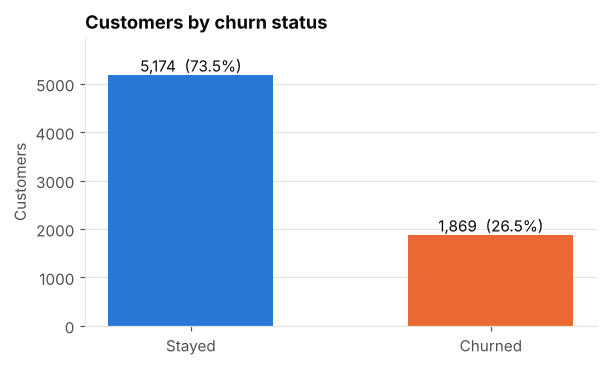

In [7]:
# churn
counts = df["Churn"].value_counts().reindex(["No", "Yes"])
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(["Stayed", "Churned"], counts.values, color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v + 80, f"{v:,}  ({v / len(df):.1%})", ha="center", color=INK)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("Customers by churn status")
ax.set_ylabel("Customers")
ax.grid(axis="x", visible=False)
plt.show()

**Findings: churn balance**

- 1,869 of 7,043 customers churned, an overall churn rate of 26.5%. Roughly one in four customers left.
- The classes are imbalanced (about 73.5% stayed), so accuracy alone would be a misleading metric for any later model. The dashed lines in the following charts mark this 26.5% baseline.

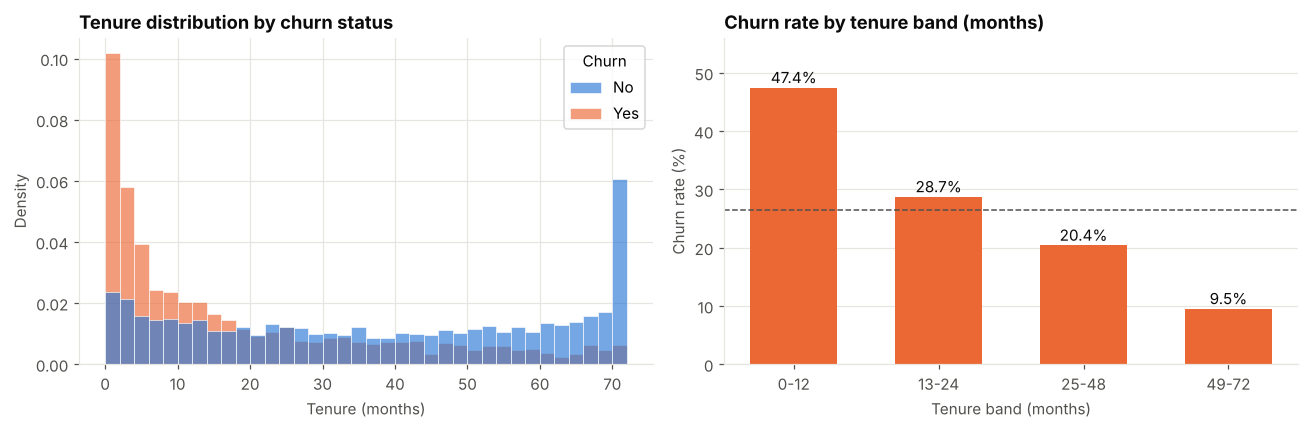

In [8]:
# tenure
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, stat="density", common_norm=False,
             palette=PAL, alpha=0.65, edgecolor="white", linewidth=0.4, ax=axes[0])
axes[0].set_title("Tenure distribution by churn status")
axes[0].set_xlabel("Tenure (months)")
df["tenure_band"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
rate_bars(axes[1], "tenure_band", title="Churn rate by tenure band (months)")
axes[1].set_xlabel("Tenure band (months)")
axes[1].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

**Findings: tenure**

- Churners are concentrated at the start of the customer lifecycle: the median tenure of churners is 10 months against 38 months for customers who stayed.
- Churn rate falls steadily with tenure: 47.4% in the first year, 28.7% in year two, 20.4% for months 25 to 48, and only 9.5% beyond four years.
- The first 12 months are the critical retention window. More than half of all churners (55.5%) left within it, even though that band holds about 31% of customers.

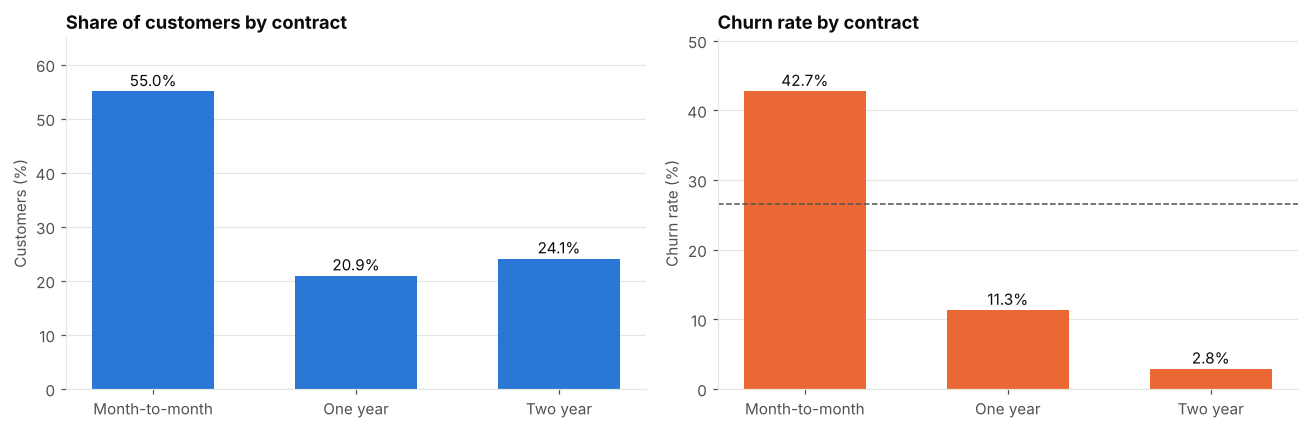

In [9]:
# contract
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = ["Month-to-month", "One year", "Two year"]
share = df["Contract"].value_counts(normalize=True).reindex(order) * 100
axes[0].bar(order, share.values, color=BLUE, width=0.6)
for i, v in enumerate(share.values):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha="center", color=INK)
axes[0].set_ylim(0, share.max() * 1.18)
axes[0].set_title("Share of customers by contract")
axes[0].set_ylabel("Customers (%)")
axes[0].grid(axis="x", visible=False)
rate_bars(axes[1], "Contract", order, "Churn rate by contract")
axes[1].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

**Findings: contract type**

- Contract type is the sharpest divider in the data. Month-to-month customers churn at 42.7%, one-year customers at 11.3%, and two-year customers at just 2.8%.
- Month-to-month is also the biggest segment (55% of customers) and accounts for 88.6% of all churners.
- Longer commitments are associated with lower churn by a factor of 4 to 15, so moving month-to-month customers onto annual plans is the clearest retention lever (with the caveat that committed customers may also simply be more loyal to begin with).

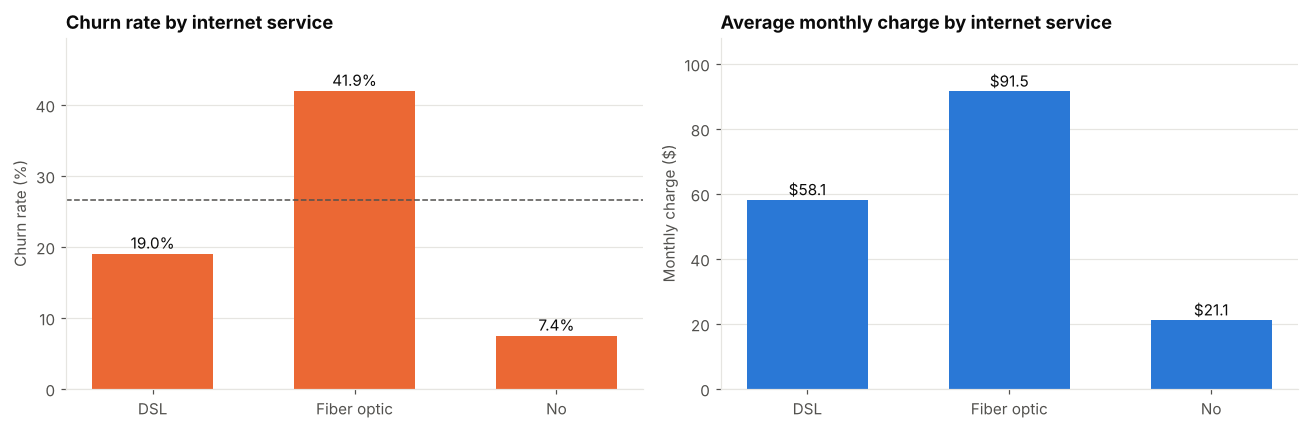

In [10]:
# internet
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = ["DSL", "Fiber optic", "No"]
rate_bars(axes[0], "InternetService", order, "Churn rate by internet service")
axes[0].set_ylabel("Churn rate (%)")
avg = df.groupby("InternetService")["MonthlyCharges"].mean().reindex(order)
axes[1].bar(order, avg.values, color=BLUE, width=0.6)
for i, v in enumerate(avg.values):
    axes[1].text(i, v + 1.5, f"${v:.1f}", ha="center", color=INK)
axes[1].set_ylim(0, avg.max() * 1.18)
axes[1].set_title("Average monthly charge by internet service")
axes[1].set_ylabel("Monthly charge ($)")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Findings: internet service**

- Fiber optic customers churn at 41.9%, more than double DSL (19.0%) and far above customers with no internet (7.4%).
- Fiber is also the most expensive product, at an average of $91.5 per month against $58.1 for DSL. Fiber customers account for 69.4% of all churners.
- High price paired with high churn suggests fiber users may be dissatisfied with value or service quality, or are being targeted by competitors. This chart alone cannot separate those causes.

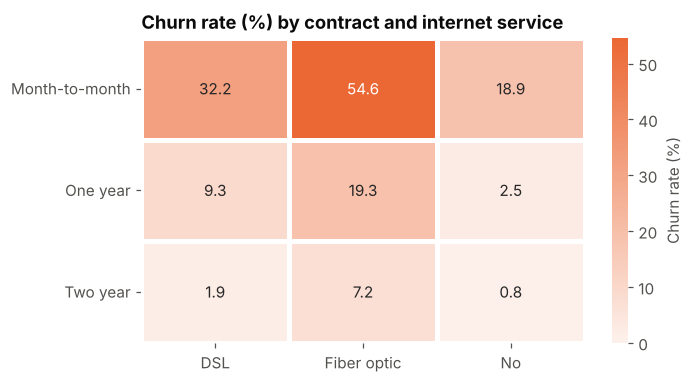

In [11]:
# heatmap
pivot = df.pivot_table(index="Contract", columns="InternetService", values="ChurnFlag", aggfunc="mean").mul(100)
pivot = pivot.reindex(["Month-to-month", "One year", "Two year"])[["DSL", "Fiber optic", "No"]]
cmap = LinearSegmentedColormap.from_list("churn", ["#fdf1ec", ORANGE])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap=cmap, vmin=0, linewidths=2, linecolor="white",
            cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate (%) by contract and internet service")
ax.set_xlabel("")
ax.set_ylabel("")
ax.grid(False)
plt.yticks(rotation=0)
plt.show()

**Findings: contract and internet combined**

- The two risk factors compound. Month-to-month fiber customers churn at 54.6%, the highest of any combination, while two-year DSL customers churn at only 1.9%.
- Contract matters inside every internet tier. Fiber customers on a one-year contract churn at 19.3% and on a two-year contract at 7.2%, so fiber itself is not the whole story.
- Month-to-month customers with fiber are the most valuable group to target for retention offers.

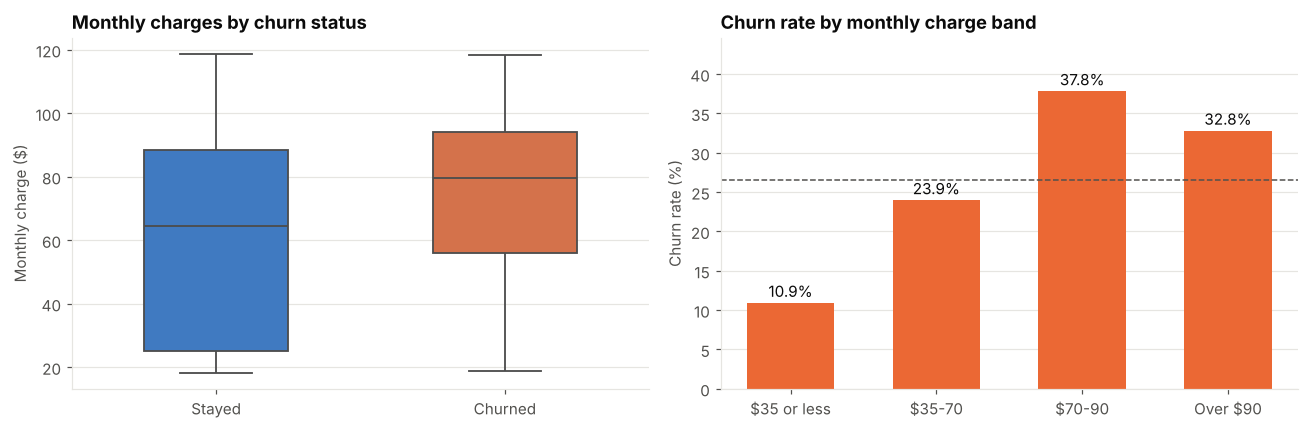

In [12]:
# charges
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=PAL, width=0.5, linewidth=1.2,
            fliersize=2, order=["No", "Yes"], ax=axes[0])
axes[0].set_xticklabels(["Stayed", "Churned"])
axes[0].set_title("Monthly charges by churn status")
axes[0].set_xlabel("")
axes[0].set_ylabel("Monthly charge ($)")
axes[0].grid(axis="x", visible=False)
df["charge_band"] = pd.cut(df["MonthlyCharges"], [0, 35, 70, 90, 120], labels=["$35 or less", "$35-70", "$70-90", "Over $90"])
rate_bars(axes[1], "charge_band", title="Churn rate by monthly charge band")
axes[1].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

**Findings: monthly charges**

- Churned customers pay more: the median is $79.60 per month against $64.40 for customers who stayed, and the lower quartile of churners ($56.20) is more than double that of retained customers ($25.10).
- Churn rises with price up to a point: 10.9% for bills of $35 or less, 23.9% for $35 to $70, and peaking at 37.8% for $70 to $90. It stays high (32.8%) above $90.
- The cheapest plans are by far the stickiest, and 88% of customers paying $35 or less have phone service only (no internet). Mid-to-high priced internet bundles carry the churn risk.

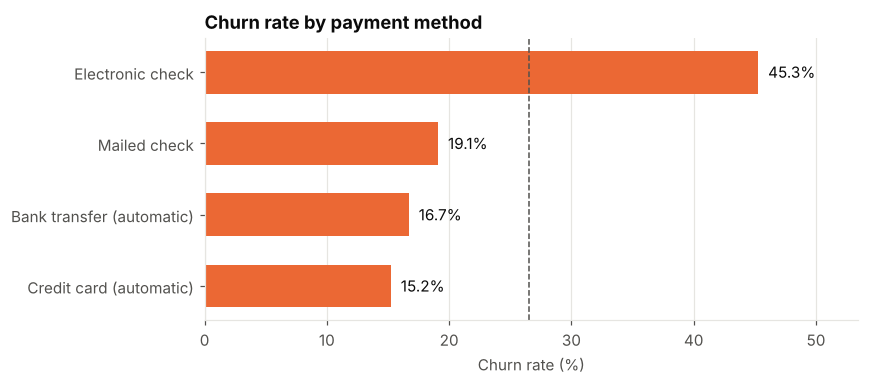

In [13]:
# payment
fig, ax = plt.subplots(figsize=(8, 3.6))
rate_bars(ax, "PaymentMethod", ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"],
          "Churn rate by payment method", horizontal=True)
ax.set_xlabel("Churn rate (%)")
plt.tight_layout()
plt.show()

**Findings: payment method**

- Electronic check users churn at 45.3%, nearly three times the rate of customers who pay by bank transfer (16.7%) or credit card (15.2%) automatically. Mailed check sits in between at 19.1%.
- Electronic check is used by 33.6% of customers but accounts for 57.3% of churners.
- Automatic payment methods look like a sign of commitment (or at least remove a recurring decision point), so nudging customers toward autopay is a low-cost retention idea.

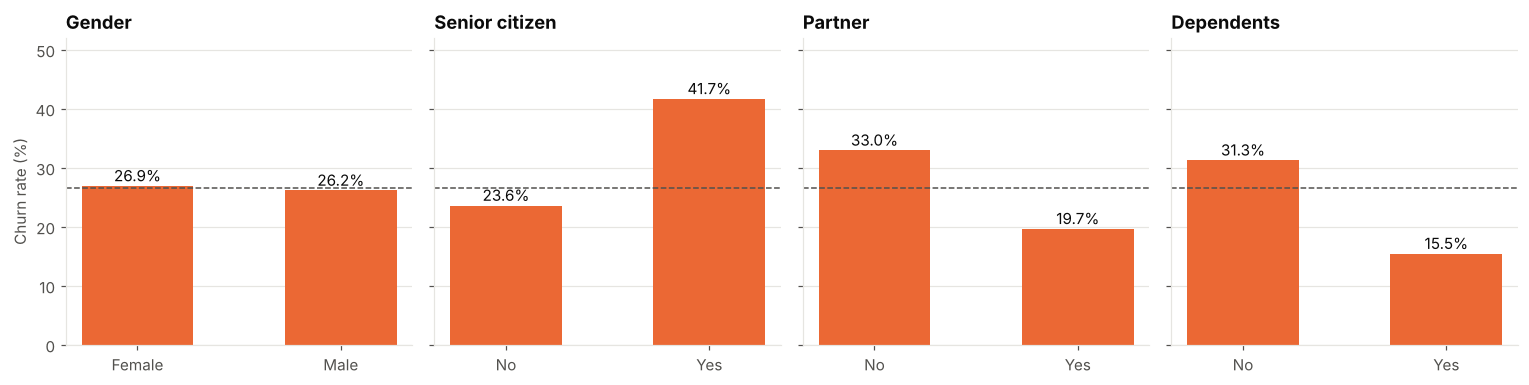

In [14]:
# demographics
d = df.copy()
d["SeniorCitizen"] = d["SeniorCitizen"].map({0: "No", 1: "Yes"})
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, col in zip(axes, ["gender", "SeniorCitizen", "Partner", "Dependents"]):
    s = d.groupby(col)["ChurnFlag"].mean().mul(100)
    ax.bar(s.index, s.values, color=ORANGE, width=0.55)
    ax.axhline(overall, color=MUTED, ls="--", lw=1)
    for i, v in enumerate(s.values):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", color=INK, fontsize=10)
    ax.set_title({"gender": "Gender", "SeniorCitizen": "Senior citizen"}.get(col, col))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 52)
plt.tight_layout()
plt.show()

**Findings: demographics**

- Gender makes no difference: 26.9% of female and 26.2% of male customers churn.
- Senior citizens churn at 41.7% versus 23.6% for non-seniors, though they are only 16.2% of the base.
- Customers without a partner (33.0% vs 19.7%) or without dependents (31.3% vs 15.5%) churn at roughly double the rate of those with them. Single-person households are the least anchored to the service.

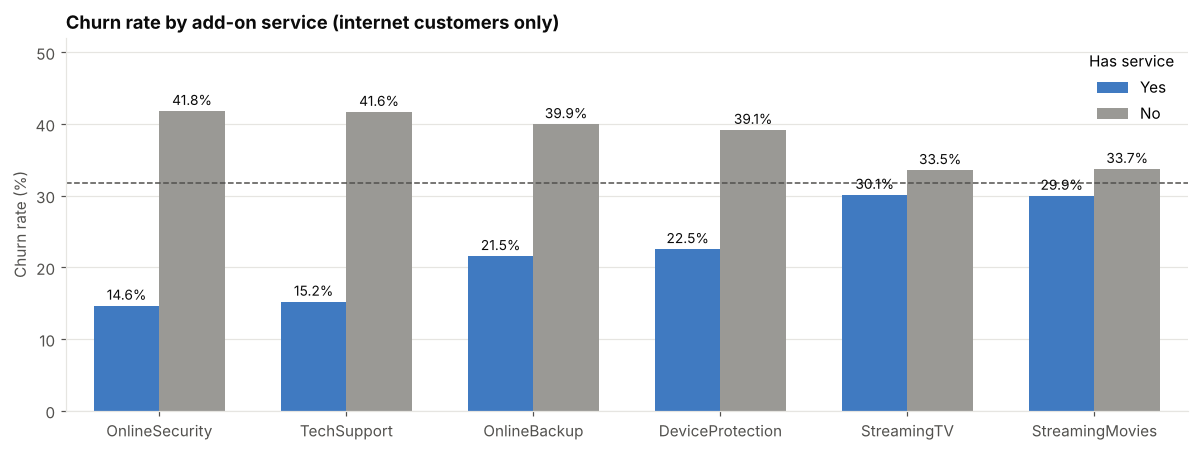

In [15]:
# addons
services = ["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]
net = df[df["InternetService"] != "No"]
rows = []
for s in services:
    for v in ["Yes", "No"]:
        rows.append({"Service": s, "Has service": v, "Churn rate": net.loc[net[s] == v, "ChurnFlag"].mean() * 100})
plot = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(11, 4.2))
sns.barplot(data=plot, x="Service", y="Churn rate", hue="Has service", hue_order=["Yes", "No"],
            palette={"Yes": BLUE, "No": GRAY}, width=0.7, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2, color=INK, fontsize=9)
ax.axhline(net["ChurnFlag"].mean() * 100, color=MUTED, ls="--", lw=1)
ax.set_title("Churn rate by add-on service (internet customers only)")
ax.set_xlabel("")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, 52)
ax.grid(axis="x", visible=False)
ax.legend(title="Has service", frameon=False)
plt.tight_layout()
plt.show()

**Findings: add-on services**

- Protective support services are strongly tied to retention. Customers with online security churn at 14.6% versus 41.8% without it, and with tech support 15.2% versus 41.6% without.
- Online backup (21.5% vs 39.9%) and device protection (22.5% vs 39.1%) show the same pattern with a smaller gap.
- Streaming services barely matter (TV 30.1% vs 33.5%, movies 29.9% vs 33.7%), so entertainment add-ons do not appear to build loyalty the way security and support do.
- The dashed line is the churn rate for internet customers overall. These are correlations: bundling security or support into plans for at-risk customers is worth testing rather than assuming.

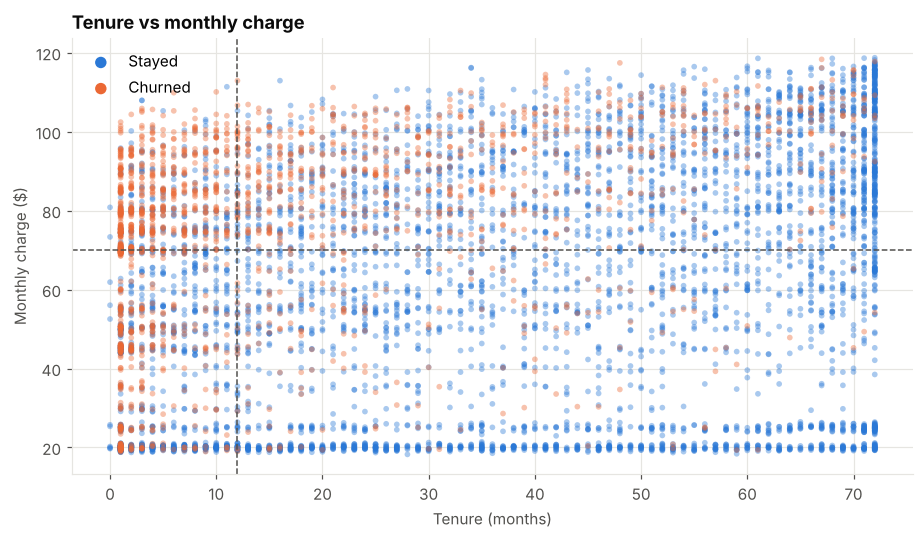

In [16]:
# scatter
fig, ax = plt.subplots(figsize=(8.5, 5))
for label, color, z in [("No", BLUE, 1), ("Yes", ORANGE, 2)]:
    sub = df[df["Churn"] == label]
    ax.scatter(sub["tenure"], sub["MonthlyCharges"], s=14, alpha=0.4, color=color, edgecolor="none",
               label="Stayed" if label == "No" else "Churned", zorder=z)
ax.axvline(12, color=MUTED, ls="--", lw=1)
ax.axhline(70, color=MUTED, ls="--", lw=1)
ax.set_title("Tenure vs monthly charge")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Monthly charge ($)")
leg = ax.legend(frameon=False, markerscale=2)
for h in leg.legend_handles:
    h.set_alpha(1)
plt.tight_layout()
plt.show()

**Findings: tenure and price together**

- Orange (churned) points pile up in the top-left: new customers with high monthly bills. Customers with 12 months or less and a bill above 70 churn at 67.9% (875 customers).
- Customers who have stayed more than 24 months and pay more than $70 churn at only 20.4% (2,230 customers). Long-tenure customers tolerate high bills far better.
- Overall, 31.8% of churners fall in the new-and-expensive quadrant, which makes onboarding quality and early pricing the key points of intervention.

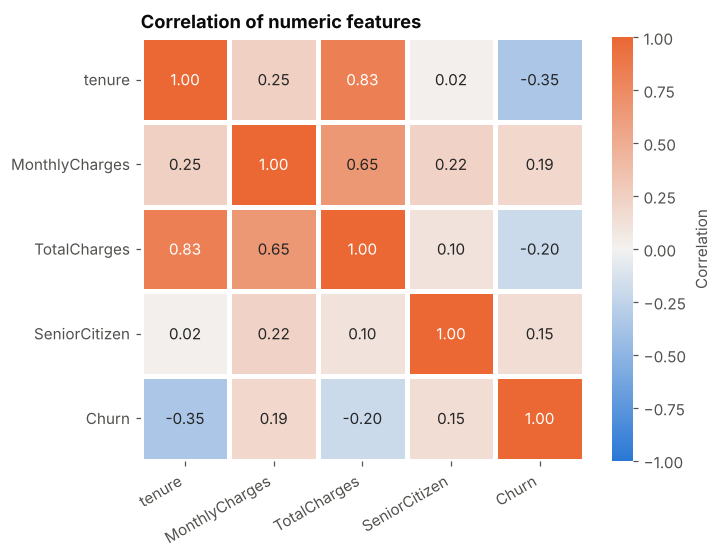

In [17]:
# correlation
num = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]].rename(columns={"ChurnFlag": "Churn"})
div = LinearSegmentedColormap.from_list("div", [BLUE, "#f2f2f0", ORANGE])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap=div, vmin=-1, vmax=1, linewidths=2, linecolor="white",
            cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlation of numeric features")
ax.grid(False)
plt.xticks(rotation=30, ha="right")
plt.show()

**Findings: correlations**

- Tenure has the strongest link to churn (-0.35): the longer a customer stays, the less likely they are to leave. Total charges is also negative (-0.20), but mostly because it grows with tenure (0.83 correlation between the two).
- Monthly charges (0.19) and senior citizen status (0.15) are positively related to churn, but all of these are moderate at best. No single numeric column explains churn, so categorical drivers such as contract matter a lot.
- `TotalCharges` is largely a product of tenure and monthly charges (0.65 with monthly charges), so it adds little independent information.

In [18]:
# model
X = pd.get_dummies(df.drop(columns=["customerID", "Churn", "ChurnFlag", "tenure_band", "charge_band"]), drop_first=True)
y = df["ChurnFlag"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [19]:
# training
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
proba = rf.predict_proba(X_test)[:, 1]
print(f"Accuracy  {accuracy_score(y_test, pred):.3f}")
print(f"ROC AUC   {roc_auc_score(y_test, proba):.3f}")
print(f"Recall    {recall_score(y_test, pred):.3f}")
print(f"Precision {precision_score(y_test, pred):.3f}")

Accuracy  0.757
ROC AUC   0.843
Recall    0.781
Precision 0.529


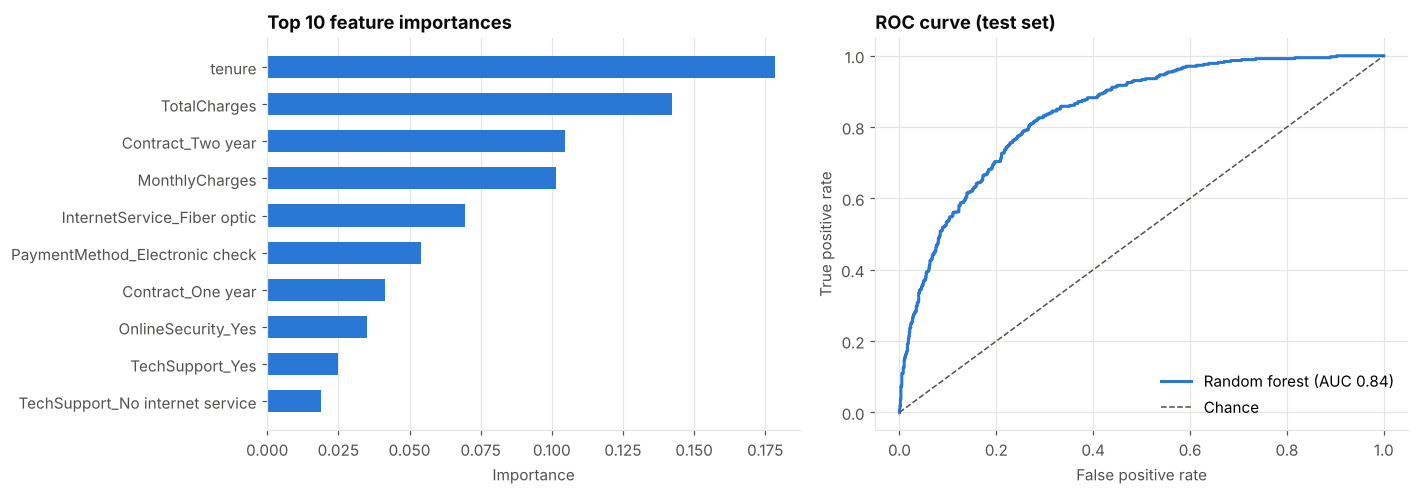

In [20]:
# importance
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
fpr, tpr, _ = roc_curve(y_test, proba)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].barh(imp.index[::-1], imp.values[::-1], color=BLUE, height=0.6)
axes[0].set_title("Top 10 feature importances")
axes[0].set_xlabel("Importance")
axes[0].grid(axis="y", visible=False)
axes[1].plot(fpr, tpr, color=BLUE, lw=2, label=f"Random forest (AUC {roc_auc_score(y_test, proba):.2f})")
axes[1].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="Chance")
axes[1].set_title("ROC curve (test set)")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Findings: model**

- A random forest trained on all features reaches an ROC AUC of about 0.84 on a held-out 20% test set, so churn is quite predictable from the account data. It catches about 78% of churners (recall) but only about 53% of its churn flags are correct (precision), a trade-off of using balanced class weights.
- The most important features line up with the charts above: tenure, total charges, a two-year contract, monthly charges, fiber optic service and electronic check payment lead the ranking.
- Security and tech support add-ons also appear in the top 10, consistent with their retention effect in the add-on chart. Importance shows predictive power, not cause, so results should be treated as targeting signals rather than proof.

## Summary

| Theme | What the data shows |
|---|---|
| Baseline | 26.5% of customers churned (1,869 of 7,043) |
| Lifecycle | Risk is highest in the first 12 months: 47.4% churn, and 55.5% of all churners leave in that window |
| Contract | Month-to-month churns at 42.7%, one-year 11.3%, two-year 2.8% |
| Product | Fiber optic churns at 41.9%; month-to-month fiber reaches 54.6% |
| Payment | Electronic check users churn at 45.3% versus about 15 to 17% on autopay |
| Support | Online security and tech support users churn at roughly a third of the rate of non-users |
| Demographics | No gender effect; seniors, singles and customers without dependents churn more |

**Suggested actions**

1. Focus retention offers on new, month-to-month, fiber customers in their first year.
2. Offer incentives to move month-to-month customers onto annual contracts.
3. Encourage autopay enrollment, especially for electronic check users.
4. Test bundling online security and tech support for at-risk customers.